In [ ]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer

from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt

import requests

In [ ]:
df = pd.read_csv('city_day (1).csv')

In [ ]:
print(f"Rows after cleaning: {len(df)}")
print(df.isna().sum())
print(df.shape)
print(df['AQI'].describe())
print(df[feature_cols].describe())

Rows after cleaning: 21122
AQI      0
PM2.5    0
PM10     0
NO2      0
CO       0
O3       0
dtype: int64
(21122, 6)
count    21122.000000
mean       121.669207
std         61.841114
min         13.000000
25%         76.000000
50%        106.000000
75%        152.000000
max        300.000000
Name: AQI, dtype: float64
              PM2.5          PM10           NO2            CO            O3
count  21122.000000  21122.000000  21122.000000  21122.000000  21122.000000
mean      49.410784     98.996394     24.587959      1.237892     33.895053
std       30.630019     56.127569     18.095443      1.965401     20.541459
min        0.040000      0.030000      0.010000      0.010000      0.010000
25%       26.720000     58.601000     11.300000      0.580000     19.080000
50%       43.360000     89.594000     19.980000      0.880000     30.340000
75%       65.635000    126.304000     33.187500      1.270000     44.827500
max      868.660000    626.630000    241.340000    101.890000    172.2800

In [ ]:
numcols = ['AQI', 'PM2.5', 'PM10', 'NO2', 'CO', 'O3']

df = df[numcols]
df = df[df['AQI'] >= 0]
df = df[df['AQI'] <= 300]

df[numcols] = df[numcols].replace(0, np.nan)

df = df[df.isna().sum(axis=1) <= 4]

df = df.dropna(subset=['AQI'])

feature_cols = ['PM2.5', 'PM10', 'NO2', 'CO', 'O3']

imputer = KNNImputer(n_neighbors=5)
df[feature_cols] = imputer.fit_transform(df[feature_cols])

In [ ]:
print(f"Rows after cleaning: {len(df)}")
print(df.isna().sum())
print(df.shape)
print(df['AQI'].describe())
print(df[feature_cols].describe())

Rows after cleaning: 21122
AQI      0
PM2.5    0
PM10     0
NO2      0
CO       0
O3       0
dtype: int64
(21122, 6)
count    21122.000000
mean       121.669207
std         61.841114
min         13.000000
25%         76.000000
50%        106.000000
75%        152.000000
max        300.000000
Name: AQI, dtype: float64
              PM2.5          PM10           NO2            CO            O3
count  21122.000000  21122.000000  21122.000000  21122.000000  21122.000000
mean      49.410784     98.996394     24.587959      1.237892     33.895053
std       30.630019     56.127569     18.095443      1.965401     20.541459
min        0.040000      0.030000      0.010000      0.010000      0.010000
25%       26.720000     58.601000     11.300000      0.580000     19.080000
50%       43.360000     89.594000     19.980000      0.880000     30.340000
75%       65.635000    126.304000     33.187500      1.270000     44.827500
max      868.660000    626.630000    241.340000    101.890000    172.2800

In [ ]:
X = df[feature_cols]
y = df['AQI']

x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
model = XGBRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(x_train_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
pred = model.predict(x_test_scaled)

mae = mean_absolute_error(y_test, pred)
mse = mean_squared_error(y_test, pred)
r2 = r2_score(y_test, pred)

print(f"MAE : {mae:.2f}")
print(f"MSE : {mse:.2f}")
print(f"R²  : {r2:.4f}")

MAE : 18.46
MSE : 729.95
R²  : 0.8024


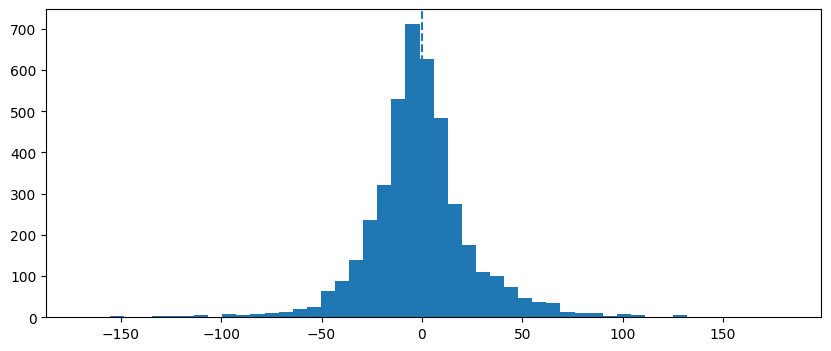

Max overestimate  : 181.36
Max underestimate : -169.67
Mean error        : -0.88
Std of error      : 27.00


In [ ]:
errors = y_test.values - pred

plt.figure(figsize=(10,4))
plt.hist(errors, bins=50)
plt.axvline(0, linestyle='--')
plt.show()

print(f"Max overestimate  : {errors.max():.2f}")
print(f"Max underestimate : {errors.min():.2f}")
print(f"Mean error        : {errors.mean():.2f}")
print(f"Std of error      : {errors.std():.2f}")

In [ ]:
single_input = np.array([
    [120.0, 200.0, 150.0, 2.5, 50.0]
])

single_scaled = scaler.transform(single_input)

predicted_aqi = model.predict(single_scaled)

print(predicted_aqi[0])

275.90323


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
API_KEY ='6200ecd2ff47f6ad62e15613c166f8df'


In [ ]:
def predict_aqi_for_city(city_name, country_code="IN"):

    url1 = f"http://api.openweathermap.org/geo/1.0/direct?q={city_name},{country_code}&limit=1&appid={API_KEY}"
    geo_data = requests.get(url1).json()

    if len(geo_data) == 0:
        print("Location not found")
        return None

    lat = geo_data[0]['lat']
    lon = geo_data[0]['lon']

    url2 = f"http://api.openweathermap.org/data/2.5/air_pollution?lat={lat}&lon={lon}&appid={API_KEY}"
    pollution_data = requests.get(url2).json()

    components = pollution_data["list"][0]["components"]

    def clip_to_range(value, col):
        return np.clip(value, df[col].min(), df[col].max())

    sample_data = np.array([[
        clip_to_range(components['pm2_5'], 'PM2.5'),
        clip_to_range(components['pm10'], 'PM10'),
        clip_to_range(components['no2'], 'NO2'),
        clip_to_range(components['co']/1000, 'CO'),
        clip_to_range(components['o3'], 'O3')
    ]])

    sample_scaled = scaler.transform(sample_data)

    predicted_aqi = model.predict(sample_scaled)[0]

    print(f"{city_name} AQI: {predicted_aqi:.2f}")

    return predicted_aqi

In [ ]:
predict_aqi_for_city("aluva")
predict_aqi_for_city("kochi")
predict_aqi_for_city("delhi")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


aluva AQI: 45.08


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


kochi AQI: 37.33
delhi AQI: 146.97


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


np.float32(146.96759)